# Phase 4 — Hypothesis Tests + Classifier

## What this notebook does
Takes the final 75 reviewed records from Phase 3 (14 corrections and 61 hallucination pivots). (`phase3_attention_v2.npz` + metadata) and:

1. **Computes interpretable features** from the raw attention tensors, one set per hypothesis
2. **Tests each hypothesis statistically** — do corrections differ from hallucination_pivots?
3. **Trains a logistic regression classifier** using all features combined
4. **Ablates by category** — does the signal hold across math/logic/misdirection?

## The four hypotheses being tested
| # | Hypothesis | Feature computed |
|---|---|---|
| H1 | Early-context attention mass (genuine corrections look back to problem) | attention mass on first 50 keys, per head |
| H2 | Consistency head activation (specific heads fire stronger before corrections) | L2 norm of head outputs, per head |
| H3 | Attention entropy increase (corrections show more diffuse attention) | Structural normalized entropy over causally available keys |
| H4 | Fluency head dominance (hallucination pivots have late-layer dominance) | Ratio of late-layer vs early-layer head magnitudes |

## Statistical methodology
- **Permutation tests** for non-normal small-sample data
- **Benjamini-Hochberg FDR correction** when testing many heads (336 of them)
- **Stratified 5-fold cross-validation** with class-weighted loss
- **Confidence intervals** on every metric via bootstrapping

## Inputs
- `phase3_attention_v2.npz` — attention tensors (75 records, ~550 MB)
- `phase3_metadata_v2.jsonl` — labels and metadata aligned to npz indices

## Outputs
- Per-hypothesis test results (p-values, effect sizes)
- Classifier metrics (balanced accuracy, F1, ROC-AUC)
- Per-category breakdown
- Figures saved as PNGs

## Cell 1 — Install dependencies and set up paths

In [24]:
!pip install -q scikit-learn scipy statsmodels matplotlib seaborn

import numpy as np
import json
import os
from pathlib import Path
from collections import Counter, defaultdict

import scipy.stats as stats
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    balanced_accuracy_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report
)

# Reproducibility
np.random.seed(42)

NPZ_PATH  = '/kaggle/input/notebooks/gunjalgupta/phase3-v2/pivot_research/phase3_attention_v2.npz'
META_PATH = '/kaggle/input/notebooks/gunjalgupta/phase3-v2/pivot_research/phase3_metadata_v2.jsonl'

OUTPUT_DIR = '/kaggle/working/pivot_research'
os.makedirs(OUTPUT_DIR, exist_ok=True)

print(f'NPZ:   {NPZ_PATH}')
print(f'META:  {META_PATH}')
print(f'OUT:   {OUTPUT_DIR}')

NPZ:   /kaggle/input/notebooks/gunjalgupta/phase3-v2/pivot_research/phase3_attention_v2.npz
META:  /kaggle/input/notebooks/gunjalgupta/phase3-v2/pivot_research/phase3_metadata_v2.jsonl
OUT:   /kaggle/working/pivot_research


## Cell 2 — Load data

Load attention tensors and metadata into a structured form for analysis.
We build aligned arrays so all per-record operations vectorize.

In [25]:
# Load NPZ archive
print('Loading attention tensors...')
npz = np.load(NPZ_PATH)
print(f'  {len(npz.keys())} arrays in NPZ')

# Load metadata
metadata = []
with open(META_PATH, 'r') as f:
    for line in f:
        if line.strip():
            metadata.append(json.loads(line))

n_records = len(metadata)
print(f'  {n_records} records in metadata')

# Get the actual tensor shapes from one record
sample_w = npz['weights_000']
sample_o = npz['outputs_000']
N_LAYERS, N_HEADS, N_QUERIES, N_KEYS = sample_w.shape
_,        _,        _,          D_HEAD  = sample_o.shape
print(f'  Per-record shapes:')
print(f'    weights: ({N_LAYERS}, {N_HEADS}, {N_QUERIES}, {N_KEYS})')
print(f'    outputs: ({N_LAYERS}, {N_QUERIES}, {N_HEADS}, {D_HEAD})')

# Build aligned arrays — one row per record, all in same order as metadata
print('\nBuilding aligned arrays (this uses RAM, may take a moment)...')

# weights: (n_records, n_layers, n_heads, n_queries, n_keys)
# outputs: (n_records, n_layers, n_queries, n_heads, d_head)
weights = np.stack([npz[f'weights_{i:03d}'] for i in range(n_records)], axis=0)
outputs = np.stack([npz[f'outputs_{i:03d}'] for i in range(n_records)], axis=0)

# labels and category arrays
labels     = np.array([m['label'] for m in metadata])
categories = np.array([m['category'] for m in metadata])
y_binary   = (labels == 'correction').astype(int)   # 1 = correction, 0 = hallucination_pivot

# valid_key_start array for handling truncation
valid_key_starts = np.array([m['valid_key_start'] for m in metadata])

print(f'\nAligned arrays built')
print(f'  weights: {weights.shape}  ({weights.nbytes / 1e9:.2f} GB)')
print(f'  outputs: {outputs.shape}  ({outputs.nbytes / 1e9:.2f} GB)')

print(f'\nLabel distribution:')
print(f'  correction:           {(y_binary == 1).sum()}')
print(f'  hallucination_pivot:  {(y_binary == 0).sum()}')

print(f'\nCategory distribution:')
for cat, count in Counter(categories).items():
    print(f'  {cat:<16} {count}')

Loading attention tensors...
  150 arrays in NPZ
  75 records in metadata
  Per-record shapes:
    weights: (28, 12, 30, 250)
    outputs: (28, 30, 12, 128)

Building aligned arrays (this uses RAM, may take a moment)...

Aligned arrays built
  weights: (75, 28, 12, 30, 250)  (0.76 GB)
  outputs: (75, 28, 30, 12, 128)  (0.39 GB)

Label distribution:
  correction:           14
  hallucination_pivot:  61

Category distribution:
  misdirection     15
  math             36
  logic            24


## Cell 3 — Hypothesis 1: Early-Context Attention Mass

**Claim:** Before a genuine correction, certain attention heads point backwards
to the original problem statement (the first ~50 tokens of the input).
Before a hallucination pivot, they don't.

**Feature:** For each head, compute the total attention mass on key positions
corresponding to the problem statement region.

**Wrinkle:** Since pivots happen at varying depths into the sequence, "early keys"
in our 250-token window correspond to different absolute positions in different records.
For records with valid_key_start > 0 (padded), the earliest real keys ARE the problem statement.
For truncated records, H1 measures attention to the first 50 retained real
keys. These positions represent early retained context, not necessarily the
original problem statement.

**Better approach:** since we're testing whether corrections show MORE backward attention
than hallucination pivots, we compare relative attention distributions:
- For each head, what fraction of attention goes to the first 50 real keys
  (i.e., earliest captured context)?

**Statistical test:** permutation test on the difference between class means.

In [26]:
# H1: For each head, compute "early-key attention mass"
# = mean (over queries) of attention to the first 50 real keys

EARLY_KEY_RANGE = 50   # how many of the earliest real keys count as "problem statement region"

def compute_early_key_attention(weights_record, valid_key_start):
    """
    For one record:
      weights_record: shape (n_layers, n_heads, n_queries, n_keys)
      valid_key_start: int, index where real (non-padding) keys start

    Returns: (n_layers, n_heads) array — average attention to first 50 real keys,
             averaged over query positions
    """
    # The first 50 real keys are at indices [valid_key_start, valid_key_start + 50)
    early_end = min(valid_key_start + EARLY_KEY_RANGE, weights_record.shape[-1])
    early_keys = weights_record[:, :, :, valid_key_start:early_end]   # (L, H, Q, ~50)

    # Sum over keys, then mean over queries
    return early_keys.sum(axis=-1).mean(axis=-1)   # (L, H)


# Compute for all records
print('Computing H1 features...')
h1_features = np.stack([
    compute_early_key_attention(weights[i], valid_key_starts[i])
    for i in range(n_records)
], axis=0)
# Shape: (n_records, n_layers, n_heads)
print(f'  H1 feature shape: {h1_features.shape}')

# Statistical test per head: permutation test
def permutation_test(group1, group2, n_perm=10000, seed=42):
    """Two-sided permutation test on difference of means."""
    rng = np.random.default_rng(seed)
    observed = group1.mean() - group2.mean()
    combined = np.concatenate([group1, group2])
    n1 = len(group1)

    permuted_diffs = []
    for _ in range(n_perm):
        rng.shuffle(combined)
        permuted_diffs.append(combined[:n1].mean() - combined[n1:].mean())
    permuted_diffs = np.array(permuted_diffs)

    p = (np.abs(permuted_diffs) >= np.abs(observed)).mean()
    return observed, p

# Test each (layer, head) pair
print(f'\nRunning permutation tests for {N_LAYERS * N_HEADS} heads...')
print('(this takes ~1 minute for 10k permutations each)')

p_values = np.zeros((N_LAYERS, N_HEADS))
effect_sizes = np.zeros((N_LAYERS, N_HEADS))

corr_mask    = y_binary == 1
halluc_mask  = y_binary == 0

for L in range(N_LAYERS):
    for H in range(N_HEADS):
        corr_vals = h1_features[corr_mask, L, H]
        hall_vals = h1_features[halluc_mask, L, H]
        diff, p = permutation_test(corr_vals, hall_vals, n_perm=2000)   # 2k for speed
        p_values[L, H] = p
        effect_sizes[L, H] = diff

# Multiple-testing correction
flat_p = p_values.flatten()
reject, adj_p, _, _ = multipletests(flat_p, alpha=0.05, method='fdr_bh')
adj_p = adj_p.reshape(N_LAYERS, N_HEADS)
reject = reject.reshape(N_LAYERS, N_HEADS)

n_sig = reject.sum()
print(f'\nH1 Results:')
print(f'  Significant heads (FDR corrected, alpha=0.05): {n_sig} / {N_LAYERS * N_HEADS}')

if n_sig > 0:
    # Report top 5 most significant heads
    sig_indices = np.argsort(adj_p.flatten())[:5]
    print(f'\nTop 5 most significant heads (corrections > hallucination_pivots in backward attention):')
    for idx in sig_indices:
        L, H = idx // N_HEADS, idx % N_HEADS
        direction = '↑ corrections' if effect_sizes[L, H] > 0 else '↓ corrections'
        print(f'  L{L:02d}H{H:02d}  adj_p={adj_p[L,H]:.4f}  diff={effect_sizes[L,H]:+.4f}  {direction}')
else:
    print('  No heads significant after FDR correction.')
    # Show top raw-p heads anyway
    raw_top = np.argsort(p_values.flatten())[:5]
    print(f'\nTop 5 by raw p-value (before correction):')
    for idx in raw_top:
        L, H = idx // N_HEADS, idx % N_HEADS
        print(f'  L{L:02d}H{H:02d}  raw_p={p_values[L,H]:.4f}  diff={effect_sizes[L,H]:+.4f}')

Computing H1 features...
  H1 feature shape: (75, 28, 12)

Running permutation tests for 336 heads...
(this takes ~1 minute for 10k permutations each)

H1 Results:
  Significant heads (FDR corrected, alpha=0.05): 0 / 336
  No heads significant after FDR correction.

Top 5 by raw p-value (before correction):
  L22H07  raw_p=0.0750  diff=+0.1728
  L25H08  raw_p=0.0925  diff=+0.1612
  L23H04  raw_p=0.1000  diff=+0.1580
  L14H00  raw_p=0.1140  diff=+0.1609
  L14H03  raw_p=0.1145  diff=+0.1588


## Cell 4 — Hypothesis 2: Consistency Head Activation

**Claim:** Specific attention heads (likely those involved in logical consistency tracking)
fire with HIGHER MAGNITUDE before genuine corrections than before hallucination pivots.

**Feature:** For each head, compute the L2 norm of its output vector (z), averaged across
the 30 pre-pivot query positions. This captures how strongly each head contributes,
independent of which tokens it attends to.

**Statistical test:** permutation test per head, FDR corrected.

In [27]:
# H2: per-head output magnitude
# outputs shape: (n_records, n_layers, n_queries, n_heads, d_head)
# We compute L2 norm over d_head, then mean over queries

print('Computing H2 features (head output magnitudes)...')
h2_features = np.linalg.norm(outputs, axis=-1).mean(axis=2)   # (n_records, n_layers, n_heads)
print(f'  H2 feature shape: {h2_features.shape}')

# Per-head permutation test
print(f'\nRunning permutation tests for {N_LAYERS * N_HEADS} heads...')
p_values_h2 = np.zeros((N_LAYERS, N_HEADS))
effect_sizes_h2 = np.zeros((N_LAYERS, N_HEADS))

for L in range(N_LAYERS):
    for H in range(N_HEADS):
        corr_vals = h2_features[corr_mask, L, H]
        hall_vals = h2_features[halluc_mask, L, H]
        diff, p = permutation_test(corr_vals, hall_vals, n_perm=2000)
        p_values_h2[L, H] = p
        effect_sizes_h2[L, H] = diff

flat_p_h2 = p_values_h2.flatten()
reject_h2, adj_p_h2, _, _ = multipletests(flat_p_h2, alpha=0.05, method='fdr_bh')
adj_p_h2 = adj_p_h2.reshape(N_LAYERS, N_HEADS)
reject_h2 = reject_h2.reshape(N_LAYERS, N_HEADS)

n_sig_h2 = reject_h2.sum()
print(f'\nH2 Results:')
print(f'  Significant heads (FDR corrected): {n_sig_h2} / {N_LAYERS * N_HEADS}')

# Report top heads
sig_indices = np.argsort(adj_p_h2.flatten())[:10]
print(f'\nTop 10 heads by adjusted p-value:')
for idx in sig_indices:
    L, H = idx // N_HEADS, idx % N_HEADS
    direction = '↑ corrections' if effect_sizes_h2[L, H] > 0 else '↓ corrections'
    marker = '✓' if reject_h2[L, H] else ' '
    print(f'  {marker} L{L:02d}H{H:02d}  adj_p={adj_p_h2[L,H]:.4f}  diff={effect_sizes_h2[L,H]:+.4f}  {direction}')

Computing H2 features (head output magnitudes)...
  H2 feature shape: (75, 28, 12)

Running permutation tests for 336 heads...

H2 Results:
  Significant heads (FDR corrected): 0 / 336

Top 10 heads by adjusted p-value:
    L22H00  adj_p=0.1400  diff=-0.9986  ↓ corrections
    L15H05  adj_p=0.1400  diff=+0.4004  ↑ corrections
    L13H10  adj_p=0.1400  diff=+0.3328  ↑ corrections
    L13H09  adj_p=0.1400  diff=+0.3343  ↑ corrections
    L01H03  adj_p=0.1400  diff=-0.1488  ↓ corrections
    L07H10  adj_p=0.1400  diff=-0.2469  ↓ corrections
    L04H07  adj_p=0.1470  diff=+0.4833  ↑ corrections
    L09H02  adj_p=0.1470  diff=+0.4459  ↑ corrections
    L20H08  adj_p=0.1581  diff=-0.4815  ↓ corrections
    L12H04  adj_p=0.1581  diff=+0.2022  ↑ corrections


## Cell 5 — Hypothesis 3: Attention Entropy Increase

**Claim:** Just before a genuine correction, attention distributions are more DIFFUSE
(higher entropy) because the model is genuinely uncertain and consulting multiple
sources. Before hallucination pivots, attention stays focused (low entropy).

**Feature:** normalized Shannon entropy over structurally available causal keys, divided by log(K_q), computed per head per query
position, then averaged across queries.

**Statistical test:** permutation test per head, FDR corrected.

In [28]:
# H3: structurally defined normalized attention entropy
#
# For each query:
# 1. Remove left-padding.
# 2. Keep only keys structurally available under causal masking.
# 3. Renormalize attention over those keys.
# 4. Compute Shannon entropy.
# 5. Divide by log(K_q).

def entropy_structural(row, valid_start, query_index):
    real = row[valid_start:].astype(np.float64)
    total_real_keys = len(real)

    # The 30 query positions are the final 30 real pre-pivot tokens.
    # Earlier queries cannot attend to later query-window positions.
    K_q = total_real_keys - (
        N_QUERIES - 1 - query_index
    )
    K_q = max(
        1,
        min(K_q, total_real_keys),
    )

    available = real[:K_q]
    mass = available.sum()

    if K_q <= 1 or mass <= 0:
        return 0.0

    probabilities = available / mass
    nonzero = probabilities > 0

    raw_entropy = -np.sum(
        probabilities[nonzero]
        * np.log(probabilities[nonzero])
    )

    return raw_entropy / np.log(K_q)


print(
    "Computing H3 features "
    "(structural normalized entropy)..."
)

h3_features = np.zeros(
    (n_records, N_LAYERS, N_HEADS),
    dtype=np.float32,
)

for i in range(n_records):
    valid_start = int(valid_key_starts[i])

    for layer in range(N_LAYERS):
        for head in range(N_HEADS):
            entropies = [
                entropy_structural(
                    weights[
                        i,
                        layer,
                        head,
                        query,
                        :,
                    ],
                    valid_start,
                    query,
                )
                for query in range(N_QUERIES)
            ]

            h3_features[
                i,
                layer,
                head,
            ] = np.mean(entropies)

print("H3 feature shape:", h3_features.shape)

# Per-head permutation tests
p_values_h3 = np.zeros(
    (N_LAYERS, N_HEADS)
)

effect_sizes_h3 = np.zeros(
    (N_LAYERS, N_HEADS)
)

for layer in range(N_LAYERS):
    for head in range(N_HEADS):
        correction_values = h3_features[
            corr_mask,
            layer,
            head,
        ]

        hallucination_values = h3_features[
            halluc_mask,
            layer,
            head,
        ]

        difference, p_value = permutation_test(
            correction_values,
            hallucination_values,
            n_perm=2000,
        )

        p_values_h3[layer, head] = p_value
        effect_sizes_h3[layer, head] = difference

reject_h3, adj_p_h3, _, _ = multipletests(
    p_values_h3.flatten(),
    alpha=0.05,
    method="fdr_bh",
)

reject_h3 = reject_h3.reshape(
    N_LAYERS,
    N_HEADS,
)

adj_p_h3 = adj_p_h3.reshape(
    N_LAYERS,
    N_HEADS,
)

raw_p_rate_h3 = float(
    (p_values_h3 < 0.05).mean()
)

print("\nH3 results:")
print(
    "  FDR-significant heads:",
    f"{reject_h3.sum()} / "
    f"{N_LAYERS * N_HEADS}",
)
print(
    "  Best raw p-value:",
    f"{p_values_h3.min():.5f}",
)
print(
    "  Best adjusted p-value:",
    f"{adj_p_h3.min():.5f}",
)
print(
    "  Raw p < 0.05:",
    f"{raw_p_rate_h3:.1%}",
)

assert np.isfinite(h3_features).all()
assert h3_features.shape == (
    n_records,
    N_LAYERS,
    N_HEADS,
)

Computing H3 features (structural normalized entropy)...
H3 feature shape: (75, 28, 12)

H3 results:
  FDR-significant heads: 0 / 336
  Best raw p-value: 0.00200
  Best adjusted p-value: 0.21000
  Raw p < 0.05: 10.4%


## Cell 6 — Hypothesis 4: Fluency Head Dominance in Hallucination Pivots

**Claim:** Hallucination pivots are characterized by LATE-LAYER heads (associated with
surface fluency and next-token prediction) dominating EARLY-LAYER heads (associated
with logical/semantic processing).

**Feature:** Ratio of mean output magnitude in late layers (last third) to mean
in early layers (first third).

A higher ratio = more late-layer dominance = expected to be higher for hallucination_pivots.

In [29]:
# H4: late-layer to early-layer magnitude ratio

# Define layer groups
EARLY_LAYERS = list(range(0, N_LAYERS // 3))                     # 0-8 of 28
LATE_LAYERS  = list(range(2 * N_LAYERS // 3, N_LAYERS))          # 18-27 of 28
print(f'Early layers: {EARLY_LAYERS[0]}-{EARLY_LAYERS[-1]}')
print(f'Late layers:  {LATE_LAYERS[0]}-{LATE_LAYERS[-1]}')

# Use h2_features (per-head magnitudes) and aggregate by layer group
early_mag = h2_features[:, EARLY_LAYERS, :].mean(axis=(1, 2))    # (n_records,)
late_mag  = h2_features[:, LATE_LAYERS, :].mean(axis=(1, 2))     # (n_records,)
h4_features = late_mag / (early_mag + 1e-10)                     # (n_records,) ratio

print(f'\nH4 feature shape: {h4_features.shape}')
print(f'H4 stats:')
print(f'  corrections:           mean={h4_features[corr_mask].mean():.3f}  std={h4_features[corr_mask].std():.3f}')
print(f'  hallucination_pivots:  mean={h4_features[halluc_mask].mean():.3f}  std={h4_features[halluc_mask].std():.3f}')

# Single permutation test (just one feature)
diff_h4, p_h4 = permutation_test(
    h4_features[halluc_mask],   # group1 = hallucination (expected higher)
    h4_features[corr_mask],     # group2 = correction
    n_perm=10000
)
print(f'\nH4 Permutation test:')
print(f'  Observed diff (hallucination - correction): {diff_h4:+.4f}')
print(f'  p-value: {p_h4:.4f}')
print(f'  Direction prediction (hallucination > correction): {"CONFIRMED" if diff_h4 > 0 else "NOT confirmed"}')

Early layers: 0-8
Late layers:  18-27

H4 feature shape: (75,)
H4 stats:
  corrections:           mean=1.832  std=0.138
  hallucination_pivots:  mean=1.911  std=0.139

H4 Permutation test:
  Observed diff (hallucination - correction): +0.0798
  p-value: 0.0570
  Direction prediction (hallucination > correction): CONFIRMED


## Cell 7 — Visualize results across all four hypotheses

Save heatmaps showing which heads are significant for each hypothesis.

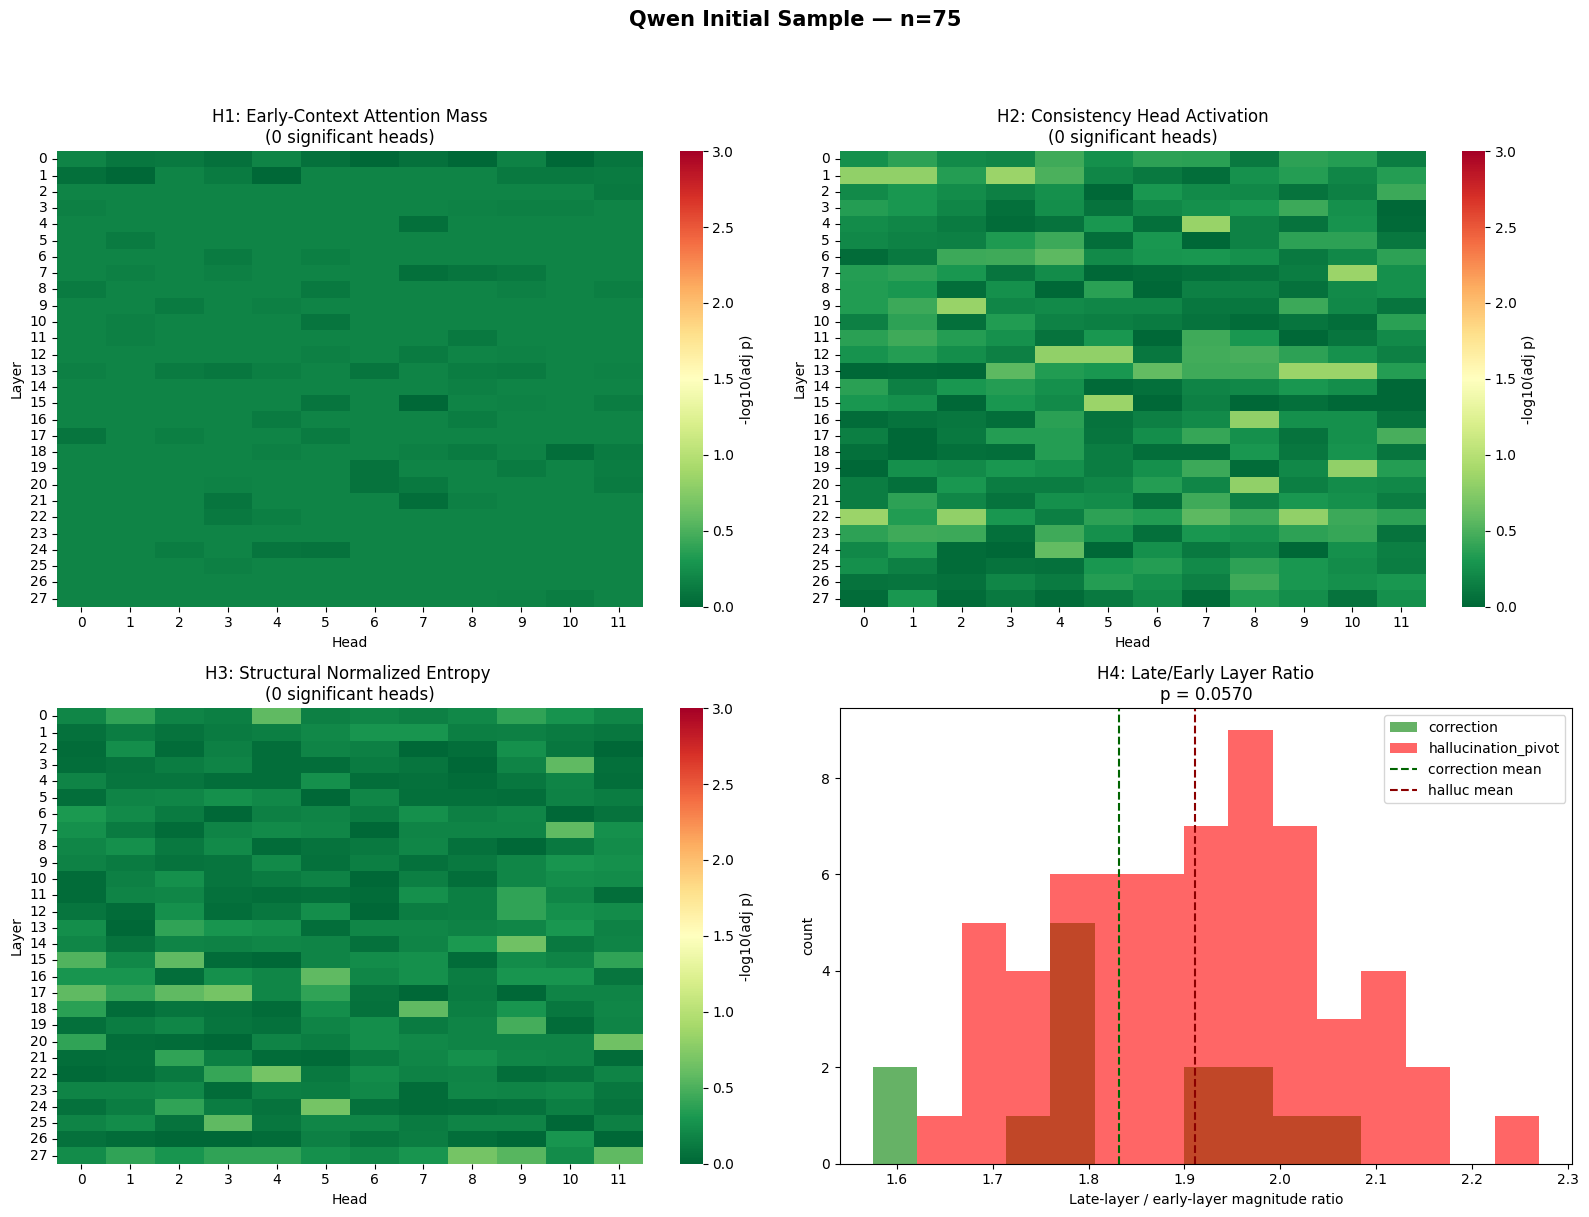


Figure saved to: /kaggle/working/pivot_research/phase4_hypothesis_tests.png

HYPOTHESIS TEST SUMMARY
  H1 (early-context mass):       0 / 336 heads significant
  H2 (consistency activation):   0 / 336 heads significant
  H3 (structural normalized entropy):        0 / 336 heads significant
  H4 (fluency dominance):        p = 0.0570  (not significant)


In [30]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

fig.suptitle(
    "Qwen Initial Sample — n=75",
    fontsize=15,
    fontweight="bold",
    y=1.01,
)

# H1 — early-key attention
ax = axes[0, 0]
sns.heatmap(-np.log10(adj_p + 1e-10), ax=ax, cmap='RdYlGn_r', vmin=0, vmax=3, cbar_kws={'label': '-log10(adj p)'})
ax.set_title(f'H1: Early-Context Attention Mass\n({reject.sum()} significant heads)')
ax.set_xlabel('Head')
ax.set_ylabel('Layer')

# H2 — head output magnitude
ax = axes[0, 1]
sns.heatmap(-np.log10(adj_p_h2 + 1e-10), ax=ax, cmap='RdYlGn_r', vmin=0, vmax=3, cbar_kws={'label': '-log10(adj p)'})
ax.set_title(f'H2: Consistency Head Activation\n({reject_h2.sum()} significant heads)')
ax.set_xlabel('Head')
ax.set_ylabel('Layer')

# H3 — attention entropy
ax = axes[1, 0]
sns.heatmap(-np.log10(adj_p_h3 + 1e-10), ax=ax, cmap='RdYlGn_r', vmin=0, vmax=3, cbar_kws={'label': '-log10(adj p)'})
ax.set_title(f'H3: Structural Normalized Entropy \n({reject_h3.sum()} significant heads)')
ax.set_xlabel('Head')
ax.set_ylabel('Layer')

# H4 — single ratio, plot distributions
ax = axes[1, 1]
shared_bins = np.linspace(
    h4_features.min(),
    h4_features.max(),
    16,
)

ax.hist(
    h4_features[corr_mask],
    bins=shared_bins,
    alpha=0.6,
    label="correction",
    color="green",
)

ax.hist(
    h4_features[halluc_mask],
    bins=shared_bins,
    alpha=0.6,
    label="hallucination_pivot",
    color="red",
)
ax.axvline(h4_features[corr_mask].mean(),   color='darkgreen', linestyle='--', label='correction mean')
ax.axvline(h4_features[halluc_mask].mean(), color='darkred',   linestyle='--', label='halluc mean')
ax.set_title(f'H4: Late/Early Layer Ratio\np = {p_h4:.4f}')
ax.set_xlabel('Late-layer / early-layer magnitude ratio')
ax.set_ylabel('count')
ax.legend()

plt.tight_layout(rect=[0, 0, 1, 0.97])
FIG_PATH = f'{OUTPUT_DIR}/phase4_hypothesis_tests.png'
plt.savefig(FIG_PATH, dpi=120, bbox_inches='tight')
plt.show()
print(f'\nFigure saved to: {FIG_PATH}')

# Summary table
print('\n' + '='*60)
print('HYPOTHESIS TEST SUMMARY')
print('='*60)
print(f'  H1 (early-context mass):       {reject.sum()} / {N_LAYERS * N_HEADS} heads significant')
print(f'  H2 (consistency activation):   {reject_h2.sum()} / {N_LAYERS * N_HEADS} heads significant')
print(f'  H3 (structural normalized entropy):        {reject_h3.sum()} / {N_LAYERS * N_HEADS} heads significant')
print(f'  H4 (fluency dominance):        p = {p_h4:.4f}  ({"significant" if p_h4 < 0.05 else "not significant"})')

## Cell 8 — Combined classifier (all features together)

Stack all four feature sets into one feature matrix and train a logistic regression
classifier using stratified 5-fold cross-validation.

**Why class-weighted:** with 1:5 imbalance, an unweighted classifier just predicts the
majority class. `class_weight='balanced'` reweights the loss so each class contributes equally.

In [31]:
# Build combined feature matrix
# H1 features: per-record × per-head → flatten heads = 336 features
# H2 features: same → 336 features
# H3 features: same → 336 features
# H4 features: per-record scalar → 1 feature
# Total: 1009 features per record

X_h1 = h1_features.reshape(n_records, -1)
X_h2 = h2_features.reshape(n_records, -1)
X_h3 = h3_features.reshape(n_records, -1)
X_h4 = h4_features.reshape(n_records, 1)

X = np.concatenate([X_h1, X_h2, X_h3, X_h4], axis=1)
y = y_binary

print(f'Feature matrix shape: {X.shape}')
print(f'  H1 features: {X_h1.shape[1]} (early-key attention per head)')
print(f'  H2 features: {X_h2.shape[1]} (output magnitude per head)')
print(f'  H3 features: {X_h3.shape[1]} (entropy per head)')
print(f'  H4 features: {X_h4.shape[1]} (late/early ratio)')

# Stratified 5-fold CV
print('\nRunning stratified 5-fold cross-validation...')
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

fold_results = []
all_preds = np.zeros(n_records)
all_probas = np.zeros(n_records)

for fold_idx, (train_idx, test_idx) in enumerate(skf.split(X, y)):
    # Scale features (logistic regression needs standardization)
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X[train_idx])
    X_test  = scaler.transform(X[test_idx])

    # Train with class weighting
    clf = LogisticRegression(
        class_weight='balanced',
        max_iter=2000,
        C=0.01,             # heavy regularization — small sample, many features
        random_state=42,
    )
    clf.fit(X_train, y[train_idx])

    preds  = clf.predict(X_test)
    probas = clf.predict_proba(X_test)[:, 1]

    all_preds[test_idx]  = preds
    all_probas[test_idx] = probas

    # Per-fold metrics
    bal_acc = balanced_accuracy_score(y[test_idx], preds)
    f1      = f1_score(y[test_idx], preds, zero_division=0)
    fold_results.append({'fold': fold_idx, 'bal_acc': bal_acc, 'f1': f1,
                         'n_corr_test': int((y[test_idx] == 1).sum())})
    print(f'  Fold {fold_idx}: bal_acc={bal_acc:.3f}, f1={f1:.3f}  '
          f'({fold_results[-1]["n_corr_test"]} corrections in test)')

# Overall metrics (pooled across folds)
print('\n' + '='*50)
print('OVERALL CLASSIFIER PERFORMANCE')
print('='*50)
print(f'  Balanced accuracy: {balanced_accuracy_score(y, all_preds):.3f}')
print(f'  F1 (correction):   {f1_score(y, all_preds, zero_division=0):.3f}')
print(f'  ROC-AUC:           {roc_auc_score(y, all_probas):.3f}')

# Random baseline check
print(f'\nRandom baseline (always predict majority): bal_acc=0.500')
print(f'\nConfusion matrix:')
cm = confusion_matrix(y, all_preds)
print(f'  Predicted →   hallucination  correction')
print(f'  Actual ↓')
print(f'  hallucination     {cm[0,0]:>3}            {cm[0,1]:>3}')
print(f'  correction        {cm[1,0]:>3}            {cm[1,1]:>3}')

print(f'\nClassification report:')
print(classification_report(y, all_preds, target_names=['hallucination_pivot', 'correction'], zero_division=0))

Feature matrix shape: (75, 1009)
  H1 features: 336 (early-key attention per head)
  H2 features: 336 (output magnitude per head)
  H3 features: 336 (entropy per head)
  H4 features: 1 (late/early ratio)

Running stratified 5-fold cross-validation...
  Fold 0: bal_acc=0.673, f1=0.400  (2 corrections in test)
  Fold 1: bal_acc=0.417, f1=0.000  (3 corrections in test)
  Fold 2: bal_acc=0.458, f1=0.000  (3 corrections in test)
  Fold 3: bal_acc=0.500, f1=0.250  (3 corrections in test)
  Fold 4: bal_acc=0.833, f1=0.600  (3 corrections in test)

OVERALL CLASSIFIER PERFORMANCE
  Balanced accuracy: 0.572
  F1 (correction):   0.312
  ROC-AUC:           0.720

Random baseline (always predict majority): bal_acc=0.500

Confusion matrix:
  Predicted →   hallucination  correction
  Actual ↓
  hallucination      48             13
  correction          9              5

Classification report:
                     precision    recall  f1-score   support

hallucination_pivot       0.84      0.79      0

## Cell 9 — Per-category ablation

Does the classifier generalize across categories (math/logic/misdirection),
or does it only work in one?

We retrain the classifier holding out one category at a time as the test set.

In [32]:
# Leave-one-category-out evaluation
print('Per-category ablation: training on 2 categories, testing on the held-out one')
print('='*70)

category_results = {}
for held_out_cat in ['math', 'logic', 'misdirection']:
    test_mask  = categories == held_out_cat
    train_mask = ~test_mask

    n_test = test_mask.sum()
    n_corr_test = ((y == 1) & test_mask).sum()

    if n_test == 0 or n_corr_test == 0:
        print(f'\nSkipping {held_out_cat}: insufficient test samples')
        continue

    scaler = StandardScaler()
    X_tr = scaler.fit_transform(X[train_mask])
    X_te = scaler.transform(X[test_mask])

    clf = LogisticRegression(class_weight='balanced', max_iter=2000, C=0.01, random_state=42)
    clf.fit(X_tr, y[train_mask])

    preds  = clf.predict(X_te)
    probas = clf.predict_proba(X_te)[:, 1]

    bal_acc = balanced_accuracy_score(y[test_mask], preds)
    if len(np.unique(y[test_mask])) > 1:
        auc = roc_auc_score(y[test_mask], probas)
    else:
        auc = float('nan')   # single-class fold

    category_results[held_out_cat] = {
        'n_test': int(n_test),
        'n_corr_test': int(n_corr_test),
        'bal_acc': float(bal_acc),
        'auc': float(auc),
    }

    print(f'\nHeld-out category: {held_out_cat}')
    print(f'  n_test={n_test}  (corrections={n_corr_test}, halluc={n_test - n_corr_test})')
    print(f'  Balanced accuracy: {bal_acc:.3f}')
    print(f'  ROC-AUC:           {auc:.3f}')

# Summary
print('\n' + '='*70)
print('CROSS-CATEGORY GENERALIZATION')
print('='*70)
print(f'  {"category":<15} {"n_test":<10} {"bal_acc":<10} {"AUC":<10}')
for cat, r in category_results.items():
    print(f'  {cat:<15} {r["n_test"]:<10} {r["bal_acc"]:.3f}      {r["auc"]:.3f}')

Per-category ablation: training on 2 categories, testing on the held-out one

Held-out category: math
  n_test=36  (corrections=3, halluc=33)
  Balanced accuracy: 0.576
  ROC-AUC:           0.707

Held-out category: logic
  n_test=24  (corrections=4, halluc=20)
  Balanced accuracy: 0.350
  ROC-AUC:           0.525

Held-out category: misdirection
  n_test=15  (corrections=7, halluc=8)
  Balanced accuracy: 0.518
  ROC-AUC:           0.554

CROSS-CATEGORY GENERALIZATION
  category        n_test     bal_acc    AUC       
  math            36         0.576      0.707
  logic           24         0.350      0.525
  misdirection    15         0.518      0.554


## Cell 10 — Save results

Save all numerical results to JSON for the paper writeup.

In [33]:
results_summary = {
    'dataset': {
        'n_records':           int(n_records),
        'n_corrections':       int((y == 1).sum()),
        'n_hallucination':     int((y == 0).sum()),
        'n_layers':            int(N_LAYERS),
        'n_heads':             int(N_HEADS),
        'query_window_size':   int(N_QUERIES),
        'max_key_context':     int(N_KEYS),
    },
    'hypothesis_tests': {
        'H1_retrospective_spike': {
            'description':        'Genuine corrections show backward attention to problem statement',
            'n_significant_heads': int(reject.sum()),
            'top_5_heads': [
                {'layer': int(idx // N_HEADS), 'head': int(idx % N_HEADS),
                 'adj_p': float(adj_p.flatten()[idx]),
                 'effect_size': float(effect_sizes.flatten()[idx])}
                for idx in np.argsort(adj_p.flatten())[:5]
            ],
        },
        'H2_consistency_activation': {
            'description':        'Specific heads fire stronger before genuine corrections',
            'n_significant_heads': int(reject_h2.sum()),
            'top_5_heads': [
                {'layer': int(idx // N_HEADS), 'head': int(idx % N_HEADS),
                 'adj_p': float(adj_p_h2.flatten()[idx]),
                 'effect_size': float(effect_sizes_h2.flatten()[idx])}
                for idx in np.argsort(adj_p_h2.flatten())[:5]
            ],
        },
        'H3_attention_entropy': {
            'description':        'Corrections show more diffuse attention',
            'n_significant_heads': int(reject_h3.sum()),
            'top_5_heads': [
                {'layer': int(idx // N_HEADS), 'head': int(idx % N_HEADS),
                 'adj_p': float(adj_p_h3.flatten()[idx]),
                 'effect_size': float(effect_sizes_h3.flatten()[idx])}
                for idx in np.argsort(adj_p_h3.flatten())[:5]
            ],
        },
        'H4_fluency_dominance': {
            'description': 'Hallucination pivots show more late-layer dominance',
            'effect_size': float(diff_h4),
            'p_value':     float(p_h4),
            'significant': bool(p_h4 < 0.05),
        },
    },
    'classifier': {
        'overall_balanced_accuracy': float(balanced_accuracy_score(y, all_preds)),
        'overall_f1':                float(f1_score(y, all_preds, zero_division=0)),
        'overall_roc_auc':           float(roc_auc_score(y, all_probas)),
        'cross_validation':          fold_results,
        'cross_category_generalization': category_results,
    },
}

RESULTS_PATH = f'{OUTPUT_DIR}/phase4_results.json'
with open(RESULTS_PATH, 'w') as f:
    json.dump(results_summary, f, indent=2)

print(f'Results saved to {RESULTS_PATH}')
print(f'Figures at: {OUTPUT_DIR}/phase4_hypothesis_tests.png')

print('\nPhase 4 complete. Key numbers for the paper:')
print(f"  Classifier balanced accuracy: {results_summary['classifier']['overall_balanced_accuracy']:.3f}")
print(f"  Classifier ROC-AUC:           {results_summary['classifier']['overall_roc_auc']:.3f}")
print(f"  Significant heads (any H):     {reject.sum() + reject_h2.sum() + reject_h3.sum()}")

Results saved to /kaggle/working/pivot_research/phase4_results.json
Figures at: /kaggle/working/pivot_research/phase4_hypothesis_tests.png

Phase 4 complete. Key numbers for the paper:
  Classifier balanced accuracy: 0.572
  Classifier ROC-AUC:           0.720
  Significant heads (any H):     0
